Import Libraries

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

Load Dataset

In [8]:
df = pd.read_csv("FakeNewsNet.csv")

df = df.dropna(subset=['title', 'real'])

X = df['title'].astype(str)
y = df['real'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Train Naive Bayes on Raw Text Features

In [9]:
raw_model = Pipeline([
    ('vectorizer', CountVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

raw_model.fit(X_train, y_train)

raw_pred = raw_model.predict(X_test)

raw_accuracy = accuracy_score(y_test, raw_pred)

print("Raw Text Accuracy:", raw_accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, raw_pred))

Raw Text Accuracy: 0.8407327586206896

Classification Report:

              precision    recall  f1-score   support

           0       0.69      0.66      0.67      1151
           1       0.89      0.90      0.89      3489

    accuracy                           0.84      4640
   macro avg       0.79      0.78      0.78      4640
weighted avg       0.84      0.84      0.84      4640



Train Naive Bayes on TF-IDF Features

In [10]:
tfidf_model = Pipeline([
    ('vectorizer', TfidfVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

tfidf_model.fit(X_train, y_train)

tfidf_pred = tfidf_model.predict(X_test)

tfidf_accuracy = accuracy_score(y_test, tfidf_pred)

print("TF-IDF Accuracy:", tfidf_accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, tfidf_pred))

TF-IDF Accuracy: 0.8213362068965517

Classification Report:

              precision    recall  f1-score   support

           0       0.85      0.34      0.49      1151
           1       0.82      0.98      0.89      3489

    accuracy                           0.82      4640
   macro avg       0.83      0.66      0.69      4640
weighted avg       0.83      0.82      0.79      4640



Compare Both Models

                 Feature Type  Accuracy
0  Raw Text (CountVectorizer)  0.840733
1                      TF-IDF  0.821336


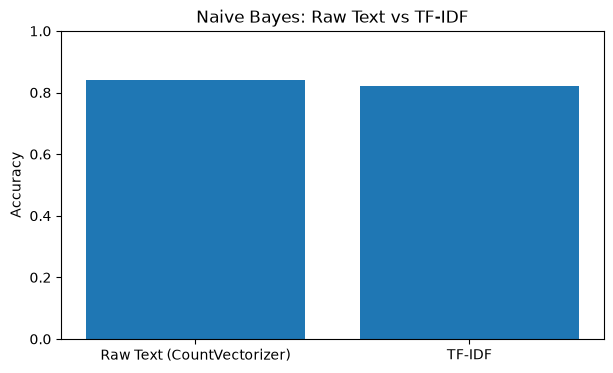

In [11]:
results = pd.DataFrame({
    'Feature Type': ['Raw Text (CountVectorizer)', 'TF-IDF'],
    'Accuracy': [raw_accuracy, tfidf_accuracy]
})

print(results)

plt.figure(figsize=(7, 4))
plt.bar(results['Feature Type'], results['Accuracy'])
plt.title('Naive Bayes: Raw Text vs TF-IDF')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()